# Just Following Methodology for dataset characterization on DT

## Libraries

In [12]:
# =========================
# 0. Imports and setup
# =========================

from pathlib import Path
import sys
import random
import time
import warnings


import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy, skew, kurtosis, zscore, kruskal, f_oneway
from scipy.spatial.distance import jensenshannon

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.feature_selection import mutual_info_classif, chi2

random.seed(42)
np.random.seed(42)

import json, platform, scipy, sklearn
from scipy.stats import spearmanr
from IPython.display import display


In [13]:
import wittgenstein
import importlib.metadata

print(importlib.metadata.version("wittgenstein"))

0.3.5


## Dataset pool preparation 

In [14]:
# =========================
# 1. Project root and datasets
# =========================

from pathlib import Path
import sys

def find_project_root(start: Path, marker="core"):
    for parent in [start] + list(start.parents):
        if (parent / marker).exists():
            return parent
    return start

PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

random.seed(42)
data_path = PROJECT_ROOT / "data"

datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

# Edit this list to only include the datasets to analyse
selected_dataset_names = list(datasets.keys())
datasets = {name: path for name, path in datasets.items() if name in selected_dataset_names}

print("Project root:", PROJECT_ROOT)
print("Data path:", data_path)
print("Datasets selected:", list(datasets.keys()))


Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees
Data path: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\data
Datasets selected: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red', 'iris', 'haberman', 'parkinsons', 'banknote', 'credit_approval']


In [15]:
# =========================
# 2. Target configuration and loader
# =========================

# Explicit target/ID handling. Values may be column names, integer positions, or
# an ordered list of fallbacks. This prevents accidental target leakage or
# target-column mistakes when the label is not the final column.
TARGET_CONFIG = {'abalone': 'target',
 'anneal': 'target',
 'arrhythmia': 'target',
 'bridges': 'target',
 'balance_scale': ['class', 'Class', 'balance', 'Balance', 0],
 'car': 'target',
 'cylinder_bands': 'target',
 'glass': 'target',
 'heart_disease': '13',
 'ionosphere': '34',
 'semeion': 'target',
 'sonar': '60',
 'tic_tac_toe': '9',
 'breast_cancer': 'target',
 'wine_red': 'target',
 'iris': 'target',
 'haberman': '3',
 'parkinsons': ['status', 'Status'],
 'banknote': '4',
 'credit_approval': '15'}

# Empty lists explicitly mean no remaining known ID columns.
# Bridges/glass IDs were removed during CSV curation.
ID_COLUMNS = {'abalone': [],
 'anneal': [],
 'arrhythmia': [],
 'bridges': [],
 'balance_scale': [],
 'car': [],
 'cylinder_bands': ['feature_001'],
 'glass': [],
 'heart_disease': [],
 'ionosphere': [],
 'semeion': [],
 'sonar': [],
 'tic_tac_toe': [],
 'breast_cancer': [],
 'wine_red': [],
 'iris': [],
 'haberman': [],
 'parkinsons': [['name', 'Name']],
 'banknote': [],
 'credit_approval': []}

MISSING_TOKENS = ["?", "NA", "N/A", "na", "n/a", "", " ", "null", "None"]


def _resolve_column(df, spec, dataset_name, purpose):
    """Resolve a column spec that can be a name, integer position, or fallback list."""
    specs = spec if isinstance(spec, (list, tuple)) else [spec]

    for candidate in specs:
        if isinstance(candidate, int):
            if -len(df.columns) <= candidate < len(df.columns):
                return df.columns[candidate]
        elif candidate in df.columns:
            return candidate

    available = list(df.columns)
    raise ValueError(
        f"Could not resolve {purpose} for {dataset_name}. "
        f"Tried {specs}; available columns: {available}"
    )


def _resolve_existing_columns(df, specs):
    """Return only the configured columns that exist in this concrete CSV."""
    resolved = []
    for spec in specs:
        try:
            col = _resolve_column(df, spec, "dataset", "ID column")
            if col not in resolved:
                resolved.append(col)
        except ValueError as exc:
            raise ValueError("Configured identifier is missing") from exc
    return resolved


def load_dataset(name, path):
    # Load a CSV and split into X and y.
    df = pd.read_csv(path, na_values=MISSING_TOKENS)
    df.columns = [str(c).strip() for c in df.columns]

    if name not in TARGET_CONFIG or name not in ID_COLUMNS:
        raise ValueError(f"Missing explicit target/ID configuration for {name}")
    target_spec = TARGET_CONFIG[name]
    target_col = _resolve_column(df, target_spec, name, "target column")

    id_cols = _resolve_existing_columns(df, ID_COLUMNS[name])
    id_cols = [c for c in id_cols if c != target_col]

    X = df.drop(columns=[target_col] + id_cols).copy()
    y = df[target_col].copy()

    valid_target = ~y.isna()
    X = X.loc[valid_target].reset_index(drop=True)
    y = y.loc[valid_target].reset_index(drop=True)

    y_encoded = LabelEncoder().fit_transform(y.astype(str))

    return {
        "df": df,
        "X": X,
        "y": y_encoded,
        "y_raw": y,
        "target_col": target_col,
        "dropped_id_cols": id_cols,
    }


loaded = {}
target_audit_rows = []

for name, path in datasets.items():
    try:
        obj = load_dataset(name, path)
        loaded[name] = obj
        y_raw = obj["y_raw"]

        target_audit_rows.append({
            "dataset": name,
            "target_col": obj["target_col"],
            "dropped_id_cols": ", ".join(obj["dropped_id_cols"]),
            "n_samples": obj["X"].shape[0],
            "n_features": obj["X"].shape[1],
            "n_classes": pd.Series(obj["y"]).nunique(),
            "min_class_count": pd.Series(obj["y"]).value_counts().min(),
            "class_counts_raw": json.dumps({str(k): int(v) for k, v in y_raw.value_counts().sort_index().items()}),
            "n_missing_targets_removed": int(obj["df"][obj["target_col"]].isna().sum()),
        })

        print(
            f"Loaded {name}: {obj['X'].shape[0]} rows, {obj['X'].shape[1]} features, "
            f"target='{obj['target_col']}', dropped_id_cols={obj['dropped_id_cols']}"
        )
    except Exception as e:
        raise ValueError(f"Could not load {name}: {e}") from e

target_audit_df = pd.DataFrame(target_audit_rows).sort_values("dataset")
target_audit_df


Loaded abalone: 4177 rows, 8 features, target='target', dropped_id_cols=[]
Loaded anneal: 798 rows, 38 features, target='target', dropped_id_cols=[]
Loaded arrhythmia: 452 rows, 279 features, target='target', dropped_id_cols=[]
Loaded bridges: 108 rows, 11 features, target='target', dropped_id_cols=[]
Loaded balance_scale: 625 rows, 4 features, target='class', dropped_id_cols=[]
Loaded car: 1728 rows, 6 features, target='target', dropped_id_cols=[]
Loaded cylinder_bands: 540 rows, 38 features, target='target', dropped_id_cols=['feature_001']
Loaded glass: 214 rows, 9 features, target='target', dropped_id_cols=[]
Loaded heart_disease: 303 rows, 13 features, target='13', dropped_id_cols=[]
Loaded ionosphere: 351 rows, 34 features, target='34', dropped_id_cols=[]
Loaded semeion: 1593 rows, 256 features, target='target', dropped_id_cols=[]
Loaded sonar: 208 rows, 60 features, target='60', dropped_id_cols=[]
Loaded tic_tac_toe: 958 rows, 9 features, target='9', dropped_id_cols=[]
Loaded bre

,dataset,target_col,dropped_id_cols,n_samples,n_features,n_classes,min_class_count,class_counts_raw,n_missing_targets_removed
0,abalone,target,,4177,8,28,1,"{""0"": 1, ""1"": 634, ""2"": 487, ""3"": 267, ""4"": 20...",0
1,anneal,target,,798,38,5,8,"{""0"": 8, ""1"": 88, ""2"": 608, ""3"": 60, ""4"": 34}",0
2,arrhythmia,target,,452,279,13,2,"{""0.0"": 245, ""1.0"": 50, ""2.0"": 4, ""3.0"": 5, ""4...",0
4,balance_scale,class,,625,4,3,49,"{""B"": 49, ""L"": 288, ""R"": 288}",0
18,banknote,4,,1372,4,2,610,"{""0"": 762, ""1"": 610}",0
13,breast_cancer,target,,569,30,2,212,"{""0.0"": 212, ""1.0"": 357}",0
3,bridges,target,,108,11,8,1,"{""0"": 13, ""1"": 11, ""2"": 10, ""3"": 1, ""4"": 44, ""...",0
5,car,target,,1728,6,4,65,"{""0"": 384, ""1"": 69, ""2"": 1210, ""3"": 65}",0
19,credit_approval,15,,690,15,2,307,"{""+"": 307, ""-"": 383}",0
6,cylinder_bands,target,feature_001,540,38,2,228,"{""0"": 228, ""2"": 312}",0


In [16]:
# PAPER-DEFINED: fail before any baseline or statistical analysis.
assert set(datasets) <= set(TARGET_CONFIG), "Every selected dataset needs a target"
assert set(loaded) == set(datasets), "Dataset loading was incomplete"
for name, obj in loaded.items():
    assert obj['X'].columns.is_unique, f"{name}: duplicate predictors"
    assert obj['target_col'] not in obj['X'], f"{name}: target leakage"
    assert len(obj['y']) > 0 and len(np.unique(obj['y'])) >= 2, f"{name}: invalid target"
    assert obj['X'].shape[1] > 0, f"{name}: no predictors"
    assert not obj['y_raw'].isna().any(), f"{name}: missing target after filtering"
    assert not set(obj['dropped_id_cols']) & set(obj['X']), f"{name}: ID leakage"
if 'parkinsons' in loaded:
    p = loaded['parkinsons']
    assert p['target_col'].lower() == 'status' and p['dropped_id_cols'] == ['name']
    assert p['X'].shape == (195, 22) and len(np.unique(p['y'])) == 2
    assert np.bincount(p['y']).min() == 48, "Unexpected Parkinsons class counts"
output_dir = PROJECT_ROOT / 'results' / 'dataset_statistics'
output_dir.mkdir(parents=True, exist_ok=True)
target_audit_df.to_csv(output_dir / 'target_audit.csv', index=False)
display(target_audit_df)


,dataset,target_col,dropped_id_cols,n_samples,n_features,n_classes,min_class_count,class_counts_raw,n_missing_targets_removed
0,abalone,target,,4177,8,28,1,"{""0"": 1, ""1"": 634, ""2"": 487, ""3"": 267, ""4"": 20...",0
1,anneal,target,,798,38,5,8,"{""0"": 8, ""1"": 88, ""2"": 608, ""3"": 60, ""4"": 34}",0
2,arrhythmia,target,,452,279,13,2,"{""0.0"": 245, ""1.0"": 50, ""2.0"": 4, ""3.0"": 5, ""4...",0
4,balance_scale,class,,625,4,3,49,"{""B"": 49, ""L"": 288, ""R"": 288}",0
18,banknote,4,,1372,4,2,610,"{""0"": 762, ""1"": 610}",0
13,breast_cancer,target,,569,30,2,212,"{""0.0"": 212, ""1.0"": 357}",0
3,bridges,target,,108,11,8,1,"{""0"": 13, ""1"": 11, ""2"": 10, ""3"": 1, ""4"": 44, ""...",0
5,car,target,,1728,6,4,65,"{""0"": 384, ""1"": 69, ""2"": 1210, ""3"": 65}",0
19,credit_approval,15,,690,15,2,307,"{""+"": 307, ""-"": 383}",0
6,cylinder_bands,target,feature_001,540,38,2,228,"{""0"": 228, ""2"": 312}",0


## Baseline performance and dataset difficulty dimensions

Baselines use macro-F1 under the same repeated stratified 5-fold protocol.

The dataset characterization is explicitly separated into three dimensions:

1. **Predictive difficulty**: low baseline macro-F1 plus high within-model CV instability.
2. **Strategy sensitivity**: disagreement between baseline algorithms.
3. **Computational burden**: runtime and tree-size/complexity indicators.

The primary Easy/Intermediate/Hard label is based only on predictive difficulty. Model spread, tree size, and runtime remain available as complementary experimental-profile descriptors, and never enter the main difficulty category.


In [17]:
def build_preprocessor(X, for_linear=False):
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if for_linear:
        numeric_steps.append(("scaler", StandardScaler()))

    # Use sparse_output when available; fall back for older scikit-learn.
    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

    transformers = []
    if numeric_cols:
        transformers.append(("num", Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", onehot),
            ]),
            categorical_cols,
        ))

    return ColumnTransformer(transformers, remainder="drop")


# PAPER-DEFINED common protocol. Runtime = elapsed seconds for all 15 CV fits
# and scores for a strategy (including pipeline and scheduling overhead).
CV_N_SPLITS, CV_N_REPEATS, CV_RANDOM_STATE = 5, 3, 42
N_JOBS = 1  # serial execution makes warning capture and timing auditable
NON_DUMMY_BASELINE_MODELS = ['decision_tree_default', 'decision_tree_balanced',
                            'logistic_regression', 'logistic_regression_balanced']
TREE_BASELINE_MODELS = NON_DUMMY_BASELINE_MODELS[:2]
DUMMY_REFERENCE_MODELS = ['dummy_most_frequent', 'dummy_stratified']
TREE_CONFIG = dict(criterion='gini', splitter='best', max_depth=None,
                   min_samples_split=2, min_samples_leaf=1, max_features=None,
                   min_weight_fraction_leaf=0.0, max_leaf_nodes=None,
                   min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0,
                   random_state=42)
LR_CONFIG = dict(penalty='l2', C=1.0, solver='lbfgs', max_iter=5000,
                 tol=1e-4, class_weight=None, random_state=42, fit_intercept=True)
MODEL_CONFIGS = {
    'decision_tree_default': TREE_CONFIG,
    'decision_tree_balanced': {**TREE_CONFIG, 'class_weight': 'balanced'},
    'logistic_regression': LR_CONFIG,
    'logistic_regression_balanced': {**LR_CONFIG, 'class_weight': 'balanced'},
    'dummy_most_frequent': dict(strategy='most_frequent', random_state=42),
    'dummy_stratified': dict(strategy='stratified', random_state=42),
}
def make_baseline(name, X):
    config = MODEL_CONFIGS[name]
    if name in DUMMY_REFERENCE_MODELS:
        return DummyClassifier(**config)
    linear = name.startswith('logistic')
    estimator = LogisticRegression(**config) if linear else DecisionTreeClassifier(**config)
    return Pipeline([('preprocess', build_preprocessor(X, for_linear=linear)),
                     ('model', estimator)])

def evaluate_baselines(data, cv_seed=42, include_dummy=True):
    from sklearn.model_selection import RepeatedStratifiedKFold
    rows, audits = [], []
    models = NON_DUMMY_BASELINE_MODELS + (DUMMY_REFERENCE_MODELS if include_dummy else [])
    for name, obj in data.items():
        X, y = obj['X'], obj['y']
        minimum = int(np.bincount(y).min())
        eligible = minimum >= CV_N_SPLITS
        issue = '' if eligible else f'min_class_count={minimum} < 5'
        audits.append(dict(dataset=name, min_class_count=minimum, comparable_cv=eligible,
                           cv_issue=issue, cv_n_splits=5, cv_n_repeats=3, cv_seed=cv_seed))
        splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3,
                      random_state=cv_seed).split(X, y)) if eligible else []
        for model_name in models:
            row = dict(dataset=name, model=model_name, cv_seed=cv_seed, cv_folds=5,
                cv_repeats=3, n_scores=0, scores=[], error=issue, warnings='',
                f1_macro_mean=np.nan, f1_macro_std=np.nan, f1_macro_min=np.nan,
                f1_macro_max=np.nan, runtime_seconds=np.nan, mean_tree_nodes=np.nan,
                mean_tree_depth=np.nan, mean_tree_leaves=np.nan)
            caught = []
            if eligible:
                try:
                    start = time.perf_counter()
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter('always')
                        result = cross_validate(make_baseline(model_name, X), X, y,
                            cv=splits, scoring=make_scorer(f1_score, average='macro', zero_division=0),
                            n_jobs=N_JOBS, error_score='raise',
                            return_estimator=model_name in TREE_BASELINE_MODELS)
                    scores = result['test_score']
                    assert len(scores) == 15 and np.isfinite(scores).all(), 'Invalid CV scores'
                    row.update(n_scores=len(scores), scores=scores.tolist(),
                        f1_macro_mean=scores.mean(), f1_macro_std=scores.std(ddof=1),
                        f1_macro_min=scores.min(), f1_macro_max=scores.max(),
                        runtime_seconds=time.perf_counter()-start)
                    if model_name in TREE_BASELINE_MODELS:
                        trees = [e.named_steps['model'].tree_ for e in result['estimator']]
                        row.update(mean_tree_nodes=np.mean([t.node_count for t in trees]),
                            mean_tree_depth=np.mean([t.max_depth for t in trees]),
                            mean_tree_leaves=np.mean([t.n_leaves for t in trees]))
                except Exception as exc:
                    row['error'] = repr(exc)
                    print(f'[FIT ERROR] {name}/{model_name}: {exc}')
                row['warnings'] = '\n'.join(sorted({f'{w.category.__name__}: {w.message}' for w in caught}))
                if row['warnings']:
                    print(f'[WARNINGS] {name}/{model_name}: {row["warnings"][:300]}')
            rows.append(row)
        print(f'CV seed {cv_seed}: {name} completed; comparable={eligible}')
    return pd.DataFrame(rows), pd.DataFrame(audits)

def successful_rows(frame):
    return (frame['error'].fillna('').eq('') & frame['n_scores'].eq(15)
            & frame['scores'].map(lambda s: len(s) == 15 and np.isfinite(s).all())
            & frame[['f1_macro_mean', 'f1_macro_std']].notna().all(axis=1))

def aggregate_baselines(frame, audit):
    good = frame.loc[successful_rows(frame) & frame.model.isin(NON_DUMMY_BASELINE_MODELS)]
    agg = good.groupby('dataset').agg(n_successful_non_dummy_models=('model','nunique'),
        baseline_macro_f1_mean=('f1_macro_mean','mean'),
        baseline_macro_f1_best=('f1_macro_mean','max'),
        baseline_macro_f1_worst=('f1_macro_mean','min'),
        mean_model_cv_f1_std=('f1_macro_std','mean')).reset_index()
    agg = audit.merge(agg, on='dataset', how='left', validate='one_to_one')
    complete = frame[frame.model.isin(NON_DUMMY_BASELINE_MODELS)].groupby('dataset').apply(
        lambda g: len(g) == 4 and set(g.model) == set(NON_DUMMY_BASELINE_MODELS)
        and successful_rows(g).all())
    agg['complete_non_dummy_protocol'] = agg.dataset.map(complete).fillna(False).astype(bool)
    agg['ranking_eligible'] = (agg.comparable_cv & agg.min_class_count.ge(5)
        & agg.complete_non_dummy_protocol
        & agg[['baseline_macro_f1_mean','mean_model_cv_f1_std']].notna().all(axis=1))
    agg['ranking_exclusion_reason'] = agg.apply(lambda r: '' if r.ranking_eligible else
        (r.cv_issue or 'Incomplete four-model protocol: inspect baseline_results.csv errors and score counts'), axis=1)
    # Partial models remain in baseline_df for inspection, never canonical aggregates.
    agg.loc[~agg.ranking_eligible, ['baseline_macro_f1_mean','baseline_macro_f1_best',
        'baseline_macro_f1_worst','mean_model_cv_f1_std']] = np.nan
    agg['baseline_macro_f1_spread'] = agg.baseline_macro_f1_best - agg.baseline_macro_f1_worst
    agg['cv_variability'] = agg.mean_model_cv_f1_std
    dummy = frame.loc[successful_rows(frame) & frame.model.isin(DUMMY_REFERENCE_MODELS)]
    agg['best_dummy_macro_f1'] = agg.dataset.map(dummy.groupby('dataset').f1_macro_mean.max())
    agg['baseline_gain_over_dummy'] = agg.baseline_macro_f1_mean - agg.best_dummy_macro_f1
    return agg

baseline_df, cv_audit_df = evaluate_baselines(loaded)
baseline_characteristics_df = aggregate_baselines(baseline_df, cv_audit_df)
display(baseline_characteristics_df)


CV seed 42: abalone completed; comparable=False
[WARNINGS] anneal/decision_tree_default: UserWarning: Skipping features without any observed values: ['feature_013']. At least one non-missing value is needed for imputation with strategy='most_frequent'.
 'fea
[WARNINGS] anneal/decision_tree_balanced: UserWarning: Skipping features without any observed values: ['feature_013']. At least one non-missing value is needed for imputation with strategy='most_frequent'.
 'fea
[WARNINGS] anneal/logistic_regression: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
Use
[WARNINGS] anneal/logistic_regression_balanced: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default

C:\Users\sarah\AppData\Local\Temp\ipykernel_31944\2895760326.py:126: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  complete = frame[frame.model.isin(NON_DUMMY_BASELINE_MODELS)].groupby('dataset').apply(


,dataset,min_class_count,comparable_cv,cv_issue,cv_n_splits,cv_n_repeats,cv_seed,n_successful_non_dummy_models,baseline_macro_f1_mean,baseline_macro_f1_best,baseline_macro_f1_worst,mean_model_cv_f1_std,complete_non_dummy_protocol,ranking_eligible,ranking_exclusion_reason,baseline_macro_f1_spread,cv_variability,best_dummy_macro_f1,baseline_gain_over_dummy
0,abalone,1,False,min_class_count=1 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=1 < 5,NaN,NaN,NaN,NaN
1,anneal,8,True,,5,3,42,4.0,0.789370,0.907593,0.619046,0.068165,True,True,,0.288547,0.068165,0.201713,0.587657
2,arrhythmia,2,False,min_class_count=2 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=2 < 5,NaN,NaN,NaN,NaN
3,bridges,1,False,min_class_count=1 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=1 < 5,NaN,NaN,NaN,NaN
4,balance_scale,49,True,,5,3,42,4.0,0.655328,0.853269,0.582401,0.022737,True,True,,0.270867,0.022737,0.329519,0.325809
5,car,65,True,,5,3,42,4.0,0.865007,0.932889,0.778573,0.031798,True,True,,0.154315,0.031798,0.245868,0.619139
6,cylinder_bands,228,True,,5,3,42,4.0,0.748329,0.761588,0.738771,0.054507,True,True,,0.022817,0.054507,0.494167,0.254162
7,glass,9,True,,5,3,42,4.0,0.621593,0.656832,0.539585,0.083331,True,True,,0.117247,0.083331,0.114581,0.507012
8,heart_disease,13,True,,5,3,42,4.0,0.301727,0.333069,0.238225,0.057831,True,True,,0.094844,0.057831,0.182116,0.119611
9,ionosphere,126,True,,5,3,42,4.0,0.871518,0.883384,0.862892,0.040564,True,True,,0.020492,0.040564,0.504045,0.367474


## Calculation of necessary inputs for score

In [18]:
# PAPER-DEFINED computational inputs, calculated once.
computational_source_df = baseline_df.loc[successful_rows(baseline_df)
    & baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)]
runtime_df = computational_source_df.groupby('dataset').agg(
    baseline_runtime_seconds_mean=('runtime_seconds','mean')).reset_index()
tree_complexity_df = computational_source_df.loc[
    computational_source_df.model.isin(TREE_BASELINE_MODELS)].groupby('dataset').agg(
    mean_tree_nodes=('mean_tree_nodes','mean'), mean_tree_depth=('mean_tree_depth','mean'),
    mean_tree_leaves=('mean_tree_leaves','mean')).reset_index()
computational_characteristics_df = pd.DataFrame({'dataset': list(loaded)}).merge(
    runtime_df, on='dataset', how='left').merge(tree_complexity_df, on='dataset', how='left')
display(computational_characteristics_df)

,dataset,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves
0,abalone,NaN,NaN,NaN,NaN
1,anneal,0.576436,130.133333,18.600000,65.566667
2,arrhythmia,NaN,NaN,NaN,NaN
3,bridges,NaN,NaN,NaN,NaN
4,balance_scale,0.126996,262.866667,11.333333,131.933333
5,car,0.254704,211.133333,13.533333,106.066667
6,cylinder_bands,0.325719,127.200000,13.566667,64.100000
7,glass,0.139693,83.666667,10.500000,42.333333
8,heart_disease,0.131278,167.533333,11.833333,84.266667
9,ionosphere,0.146240,44.400000,8.766667,22.700000


In [19]:
# Multi-dimensional dataset profile
# =====================================
# Paper-aligned implementation of Sections 3.3 and 3.4.
#
# Assumptions from upstream cells:
# - baseline_macro_f1_mean = F_d, mean macro-F1 across NON-DUMMY baselines.
# - mean_model_cv_f1_std = V_d, mean within-model CV std across NON-DUMMY baselines.
# - baseline_macro_f1_spread = S_d, range of model-level mean macro-F1 across NON-DUMMY baselines.
# - the target/eligibility audit (min class count >= k=5) was already applied before baseline evaluation.


def minmax_normalize_on_pool(series, pool_mask):
    """Min-max normalize using only the eligible benchmark pool."""
    values = pd.to_numeric(series, errors="coerce")
    pool_mask = pd.Series(pool_mask, index=values.index).fillna(False).astype(bool)

    result = pd.Series(np.nan, index=values.index, dtype=float)
    valid = pool_mask & values.notna()

    if valid.sum() == 0:
        return result

    min_val = values.loc[valid].min()
    max_val = values.loc[valid].max()

    if max_val == min_val:
        result.loc[valid] = 0.0
        return result

    result.loc[valid] = (
        values.loc[valid] - min_val
    ) / (
        max_val - min_val
    )

    return result


# ------------------------------------------------------------------
# Base dataset-level profile
# ------------------------------------------------------------------

dataset_profile_df = baseline_characteristics_df.copy()

# Eligibility was established from all four complete model evaluations.

# ============================================================
# 1. Predictive difficulty
# ============================================================
#
# F_d = mean macro-F1 across non-dummy baseline strategies
# E_d = 1 - F_d
# V_d = mean within-model cross-validation variability
#
# D_pred_d = 0.70 * z(E_d) + 0.30 * z(V_d)


dataset_profile_df["predictive_error"] = (
    1.0 - dataset_profile_df["baseline_macro_f1_mean"]
)

dataset_profile_df["cv_variability"] = (
    dataset_profile_df["mean_model_cv_f1_std"]
)

dataset_profile_df["predictive_error_score"] = minmax_normalize_on_pool(
    dataset_profile_df["predictive_error"],
    dataset_profile_df["ranking_eligible"],
)

dataset_profile_df["cv_variability_score"] = minmax_normalize_on_pool(
    dataset_profile_df["cv_variability"],
    dataset_profile_df["ranking_eligible"],
)

dataset_profile_df["predictive_difficulty_score"] = (
    0.70 * dataset_profile_df["predictive_error_score"]
    + 0.30 * dataset_profile_df["cv_variability_score"]
)


# ============================================================
# 2. Strategy sensitivity
# ============================================================
#
# S_d = max_m(mu_d,m) - min_m(mu_d,m)
#
# This is a complementary descriptor. It does NOT modify the
# Easy / Intermediate / Hard predictive-difficulty label.


dataset_profile_df["strategy_sensitivity"] = (
    dataset_profile_df["baseline_macro_f1_spread"]
)

dataset_profile_df["strategy_sensitivity_score"] = minmax_normalize_on_pool(
    dataset_profile_df["strategy_sensitivity"],
    dataset_profile_df["ranking_eligible"],
)


# ============================================================
# 3. Computational burden
# ============================================================
#
# D_comp_d = [z(T_d) + z(N_d)] / 2
#
# T_d = mean runtime across non-dummy baseline strategies
# N_d = mean node count across decision-tree baselines
#
# Tree depth and leaves are retained for interpretation only.


computational_columns = [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "runtime_burden_score",
    "tree_size_burden_score",
    "computational_burden_score",
]

dataset_profile_df = dataset_profile_df.drop(
    columns=[
        col for col in computational_columns
        if col in dataset_profile_df.columns
    ],
    errors="ignore",
)

dataset_profile_df = dataset_profile_df.merge(
    computational_characteristics_df,
    on="dataset",
    how="left",
)

runtime_col = "baseline_runtime_seconds_mean"
tree_size_col = "mean_tree_nodes"

if runtime_col in dataset_profile_df.columns:
    dataset_profile_df["runtime_burden_score"] = minmax_normalize_on_pool(
        dataset_profile_df[runtime_col],
        dataset_profile_df["ranking_eligible"],
    )
else:
    dataset_profile_df["runtime_burden_score"] = np.nan

if tree_size_col in dataset_profile_df.columns:
    dataset_profile_df["tree_size_burden_score"] = minmax_normalize_on_pool(
        dataset_profile_df[tree_size_col],
        dataset_profile_df["ranking_eligible"],
    )
else:
    dataset_profile_df["tree_size_burden_score"] = np.nan

# Equation (9) requires both normalized components.
dataset_profile_df["computational_burden_score"] = np.nan

complete_comp_mask = (
    dataset_profile_df["runtime_burden_score"].notna()
    & dataset_profile_df["tree_size_burden_score"].notna()
)

dataset_profile_df.loc[
    complete_comp_mask,
    "computational_burden_score",
] = (
    dataset_profile_df.loc[
        complete_comp_mask,
        ["runtime_burden_score", "tree_size_burden_score"],
    ].mean(axis=1)
)


# ============================================================
# 4. Easy / Intermediate / Hard subset construction
# ============================================================
#
# Primary ordering: D_pred ascending.
# Secondary criteria are used only for numerically tied scores:
#   1. higher mean macro-F1 first;
#   2. lower CV variability first.
# Dataset name is only a deterministic final tie-break.
#
# The ordered eligible collection is split into three approximately
# equal-sized groups. Non-eligible datasets remain review_separately.


# Only exactly equal floating-point scores are ties; no near-tie rounding.
SCORE_TIE_ATOL = 0.0

def assign_predictive_difficulty_groups(df):
    labels = pd.Series("review_separately", index=df.index, dtype="object")
    ranks = pd.Series(np.nan, index=df.index, dtype=float)

    valid = (
        df["ranking_eligible"]
        & df["predictive_difficulty_score"].notna()
        & df["baseline_macro_f1_mean"].notna()
        & df["cv_variability"].notna()
    )

    if valid.sum() == 0:
        return labels, ranks

    ranked = df.loc[
        valid,
        [
            "dataset",
            "predictive_difficulty_score",
            "baseline_macro_f1_mean",
            "cv_variability",
        ],
    ].copy()

    # Exact equality implements SCORE_TIE_ATOL = 0 consistently in all analyses.
    ranked["_score_tie_key"] = (
        ranked["predictive_difficulty_score"]
    )

    ranked = ranked.sort_values(
        [
            "_score_tie_key",
            "baseline_macro_f1_mean",
            "cv_variability",
            "dataset",
        ],
        ascending=[True, False, True, True],
        kind="mergesort",
    )

    ranks.loc[ranked.index] = np.arange(1, len(ranked) + 1)

    thirds = np.array_split(ranked.index.to_numpy(), 3)

    for label, indices in zip(
        ["easy", "intermediate", "hard"],
        thirds,
    ):
        labels.loc[indices] = label

    return labels, ranks


(
    dataset_profile_df["predictive_difficulty_label"],
    dataset_profile_df["predictive_difficulty_rank"],
) = assign_predictive_difficulty_groups(dataset_profile_df)


dataset_profile_df["difficulty_label_assignment_note"] = (
    "Relative benchmark-pool strata assigned from "
    "D_pred = 0.70*z(E) + 0.30*z(V). Strategy sensitivity and "
    "computational burden are complementary descriptors and do not "
    "determine the Easy/Intermediate/Hard label."
)


# ============================================================
# 5. Monotonicity audit
# ============================================================
#
# The paper verifies:
# mean(F)_Easy > mean(F)_Intermediate > mean(F)_Hard
#
# Mean is used because predictive error E_d is itself derived from
# mean baseline macro-F1.


ordered_labels = ["easy", "intermediate", "hard"]

predictive_monotonicity_df = (
    dataset_profile_df[
        dataset_profile_df["predictive_difficulty_label"].isin(
            ordered_labels
        )
    ]
    .groupby("predictive_difficulty_label", observed=True)
    .agg(
        n_datasets=("dataset", "nunique"),
        mean_baseline_macro_f1=("baseline_macro_f1_mean", "mean"),
        min_baseline_macro_f1=("baseline_macro_f1_mean", "min"),
        max_baseline_macro_f1=("baseline_macro_f1_mean", "max"),
        mean_cv_variability=("cv_variability", "mean"),
        mean_strategy_sensitivity=("strategy_sensitivity", "mean"),
        mean_computational_burden=("computational_burden_score", "mean"),
    )
    .reindex(ordered_labels)
    .reset_index()
)

group_means = (
    predictive_monotonicity_df
    .set_index("predictive_difficulty_label")["mean_baseline_macro_f1"]
)

is_monotonic_f1 = (
    group_means.notna().all()
    and group_means["easy"] > group_means["intermediate"]
    and group_means["intermediate"] > group_means["hard"]
)

print(
    "Monotonic predictive difficulty "
    "(Easy > Intermediate > Hard):",
    bool(is_monotonic_f1),
)


# ============================================================
# 6. Export and display
# ============================================================


dataset_profile_df.to_csv(
    output_dir / "dataset_experimental_profile.csv",
    index=False,
)

predictive_monotonicity_df.to_csv(
    output_dir / "predictive_difficulty_monotonicity_check.csv",
    index=False,
)


display(predictive_monotonicity_df)

ranking_columns = [
    "dataset",
    "baseline_macro_f1_mean",       # F_d
    "predictive_error_score",       # z(E_d)
    "cv_variability_score",         # z(V_d)
    "predictive_difficulty_score",  # D_pred_d
    "predictive_difficulty_rank",
    "predictive_difficulty_label",
    "strategy_sensitivity",         # S_d
    "strategy_sensitivity_score",
]

for optional_col in [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "computational_burden_score",
]:
    if optional_col in dataset_profile_df.columns:
        ranking_columns.append(optional_col)


display(
    dataset_profile_df[ranking_columns]
    .sort_values(
        ["predictive_difficulty_rank", "dataset"],
        na_position="last",
    )
)


Monotonic predictive difficulty (Easy > Intermediate > Hard): True


,predictive_difficulty_label,n_datasets,mean_baseline_macro_f1,min_baseline_macro_f1,max_baseline_macro_f1,mean_cv_variability,mean_strategy_sensitivity,mean_computational_burden
0,easy,6,0.921721,0.835524,0.981649,0.021520,0.076405,0.214889
1,intermediate,6,0.779652,0.655328,0.871518,0.048501,0.122228,0.184046
2,hard,5,0.513595,0.301727,0.744293,0.059619,0.097967,0.200235


,dataset,baseline_macro_f1_mean,predictive_error_score,cv_variability_score,predictive_difficulty_score,predictive_difficulty_rank,predictive_difficulty_label,strategy_sensitivity,strategy_sensitivity_score,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves,computational_burden_score
18,banknote,0.981649,0.000000,0.000000,0.000000,1.0,easy,0.001419,0.000000,0.113703,54.466667,7.500000,27.733333,0.041632
12,tic_tac_toe,0.947386,0.050392,0.110116,0.068309,2.0,easy,0.070705,0.241308,0.171654,138.466667,10.933333,69.733333,0.139365
13,breast_cancer,0.949823,0.046807,0.160305,0.080856,3.0,easy,0.051007,0.172705,0.152859,37.266667,6.800000,19.133333,0.054976
15,iris,0.950938,0.045168,0.439209,0.163380,4.0,easy,0.004489,0.010694,0.102851,14.600000,4.866667,7.800000,0.006134
10,semeion,0.835524,0.214913,0.108214,0.182904,5.0,easy,0.176497,0.609757,0.858257,438.200000,15.166667,219.600000,0.801795
5,car,0.865007,0.171552,0.325091,0.217614,6.0,easy,0.154315,0.532503,0.254704,211.133333,13.533333,106.066667,0.245432
9,ionosphere,0.871518,0.161975,0.439902,0.245353,7.0,intermediate,0.020492,0.066427,0.146240,44.400000,8.766667,22.700000,0.055731
19,credit_approval,0.829559,0.223687,0.390546,0.273745,8.0,intermediate,0.068720,0.234393,0.233927,154.533333,12.766667,77.766667,0.191524
4,balance_scale,0.655328,0.479939,0.206419,0.397883,9.0,intermediate,0.270867,0.938427,0.126996,262.866667,11.333333,131.933333,0.198797
6,cylinder_bands,0.748329,0.343156,0.622500,0.426960,10.0,intermediate,0.022817,0.074526,0.325719,127.200000,13.566667,64.100000,0.232062


## Cross-Model Validation of Dataset Difficulty

This complementary experiment preserves all original cells, outputs, configurations,
scores and labels. Decision Tree and Logistic Regression reuse `baseline_df`.
Only SVM-RBF and RIPPER are fitted, with the original repeated stratified 5-fold CV,
3 repeats, seed 42, macro-F1 and sample SD (`ddof=1`).

**Controls:** `CROSS_MODE="quick"` runs banknote, iris and glass (15 folds each).
Use `"full"` for all originally ranking-eligible datasets, or `"resume"` with
`CROSS_DATASETS=["glass"]` for individual datasets. `CROSS_MODELS` selects new models.
Completed folds are checkpointed; interrupt slow fits and rerun to resume. No automatic
timeout, model substitution, tuning or fold reduction. Running the whole notebook still
executes the unchanged original baseline cell; rerunning this section reuses results.

The only new dependency is `wittgenstein`; install in the kernel environment if missing:
`%pip install wittgenstein==0.3.5`. Installation is not automatic. Compatibility is
checked before evaluation with binary/multiclass clone/fit/predict, including nominal
and missing values. Failures are exported explicitly. Adapter verified with Python 3.12.12, wittgenstein 0.3.5 and
scikit-learn 1.8.0 (binary/multiclass fit, predict and predict_proba). See [RIPPER documentation](https://github.com/imoscovitz/wittgenstein)
and [OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html).

SVM reuses `build_preprocessor(..., for_linear=True)`. RIPPER uses fold-local median/mode
imputation and native nominal strings, avoiding one-hot expansion and artificial ordinal
ordering. RIPPER learns numeric discretization inside training folds. Defaults and
versions are exported in the manifest. Entirely missing training columns use constant
0 (numeric) or `__MISSING__` (nominal); this does not impute missing performance metrics.

Compatibility update: `SklearnRIPPER(ClassifierMixin, wittgenstein.RIPPER, BaseEstimator)`
provides sklearn classifier tags, with the mixin before BaseEstimator. RIPPER constructor,
fit, predict, predict_proba and hyperparameters are inherited unchanged. The probe checks
classifier tags, clones, Pipeline/OvR, predictions and normalized probabilities before CV.
On failure, the full traceback is retained in the compatibility result and manifest.

Verification: all 15 folds for banknote, iris and glass passed for both models;
SVM legacy-cache reuse and one-fold resume were tested. Adapter predictions and
probabilities matched native RIPPER on a binary parity test. Re-execute this setup
cell first and check `RIPPER_COMPATIBILITY["status"] == "complete"`, then rerun
the incremental evaluation and reporting cells. Earlier baseline cells need not rerun.


In [20]:
import hashlib
import importlib.metadata
import traceback
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone, is_classifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.svm import SVC

CROSS_MODE = "full"  # quick, full, resume
CROSS_DATASETS = ["glass"]  # resume mode only
CROSS_MODELS = ["svm_rbf", "ripper"]
SLOW_FOLD_SECONDS = 120  # logging only
CROSS_DIR = output_dir / "cross_model_validation"
CROSS_DIR.mkdir(parents=True, exist_ok=True)
assert (CV_N_SPLITS, CV_N_REPEATS, CV_RANDOM_STATE) == (5, 3, 42)
CROSS_FAMILIES = {
    "Decision Tree": list(TREE_BASELINE_MODELS),
    "Logistic Regression": ["logistic_regression", "logistic_regression_balanced"],
    "SVM-RBF": ["svm_rbf"], "RIPPER": ["ripper"]}
SVM_CONFIG = dict(kernel="rbf", C=1.0, gamma="scale", class_weight=None)
CROSS_VERSIONS = {p: importlib.metadata.version(p) for p in
                  ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]}
CROSS_VERSIONS["python"] = platform.python_version()
try:
    import wittgenstein
    CROSS_VERSIONS["wittgenstein"] = importlib.metadata.version("wittgenstein")
    RIPPER_CONFIG = wittgenstein.RIPPER(random_state=42).get_params()
    RIPPER_IMPORT_ERROR = ""
except ImportError as exc:
    RIPPER_CONFIG = None
    CROSS_VERSIONS["wittgenstein"] = "unavailable"
    RIPPER_IMPORT_ERROR = repr(exc)

class RipperPreprocessor(TransformerMixin, BaseEstimator):
    """Fold-local imputation preserving numeric and nominal feature types."""
    def fit(self, X, y=None):
        self.columns_ = list(X.columns)
        self.numeric_ = set(X.select_dtypes(include=[np.number]).columns)
        self.fill_ = {}
        for c in self.columns_:
            values = X[c].dropna()
            self.fill_[c] = ((values.median() if len(values) else 0.0) if c in self.numeric_
                else str(values.astype(str).mode().iloc[0]) if len(values) else "__MISSING__")
        return self
    def transform(self, X):
        out = X.loc[:, self.columns_].copy()
        for c in self.columns_:
            out[c] = (pd.to_numeric(out[c]).fillna(self.fill_[c]).astype(float) if c in self.numeric_
                else out[c].astype(object).where(out[c].notna(), self.fill_[c]).astype(str))
        return out

if not RIPPER_IMPORT_ERROR:
    class SklearnRIPPER(ClassifierMixin, wittgenstein.RIPPER, BaseEstimator):
        """Only sklearn metadata: inherit RIPPER's constructor, fit and predictions."""
        def __sklearn_tags__(self):
            tags = super().__sklearn_tags__()
            tags.classifier_tags.multi_class = False  # native RIPPER is binary; OvR handles multiclass
            return tags


def make_svm_model(X):
    return Pipeline([("preprocess", build_preprocessor(X, for_linear=True)),
                     ("model", SVC(**SVM_CONFIG))])

def make_cross_model(model, X, y):
    if model == "svm_rbf":
        return make_svm_model(X)
    if model != "ripper":
        raise ValueError(f"Unknown model: {model}")
    if RIPPER_IMPORT_ERROR:
        raise ImportError(RIPPER_IMPORT_ERROR)
    estimator = SklearnRIPPER(random_state=42)
    if len(np.unique(y)) > 2:
        estimator = OneVsRestClassifier(estimator, n_jobs=1)
    return Pipeline([("preprocess", RipperPreprocessor()), ("model", estimator)])

def check_cross_predictions(y, predicted):
    predicted = np.asarray(predicted)
    if predicted.ndim != 1 or len(predicted) != len(y) or not np.isin(predicted, np.unique(y)).all():
        raise ValueError("Invalid prediction shape or unknown class")
    score = float(f1_score(y, predicted, average="macro", zero_division=0))
    if not np.isfinite(score) or not 0 <= score <= 1:
        raise ValueError("Invalid macro-F1")
    return score

def check_ripper_compatibility():
    caught = []
    try:
        if RIPPER_IMPORT_ERROR:
            raise ImportError(RIPPER_IMPORT_ERROR)
        raw = SklearnRIPPER(random_state=42)
        if not is_classifier(raw) or not is_classifier(clone(raw)):
            raise TypeError("SklearnRIPPER/clone missing classifier tags")
        if raw.get_params() != wittgenstein.RIPPER(random_state=42).get_params():
            raise ValueError("RIPPER hyperparameters changed")
        from sklearn.datasets import load_iris
        X, y = load_iris(return_X_y=True, as_frame=True)
        X["nominal"] = np.where(np.arange(len(X)) % 2, "a", "b")
        X.loc[0, X.columns[0]] = np.nan
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            for target in [(y > 0).astype(int).to_numpy(), y.to_numpy()]:
                pipe = clone(make_cross_model("ripper", X, target))
                if not is_classifier(pipe):
                    raise TypeError("Installed sklearn does not recognize RIPPER as a classifier")
                train, test = next(RepeatedStratifiedKFold(n_splits=5, n_repeats=3,
                                  random_state=42).split(X, target))
                pipe.fit(X.iloc[train], target[train])
                check_cross_predictions(target[test], pipe.predict(X.iloc[test]))
                probabilities = np.asarray(pipe.predict_proba(X.iloc[test]))
                expected = (len(test), len(np.unique(target)))
                if (probabilities.shape != expected or not np.isfinite(probabilities).all()
                    or (probabilities < 0).any() or (probabilities > 1).any()
                    or not np.allclose(probabilities.sum(axis=1), 1.0)):
                    raise ValueError(f"Invalid predict_proba output; expected {expected}")
                fitted = pipe.named_steps["model"]
                members = fitted.estimators_ if isinstance(fitted, OneVsRestClassifier) else [fitted]
                if not all(is_classifier(m) and is_classifier(clone(m)) for m in members):
                    raise TypeError("Fitted RIPPER/OvR member missing classifier tags")
        return dict(status="complete", error="", warnings=[str(w.message) for w in caught])
    except Exception:
        return dict(status="compatibility_error", error=traceback.format_exc(),
                    warnings=[str(w.message) for w in caught])

RIPPER_COMPATIBILITY = check_ripper_compatibility()
print("RIPPER compatibility:", RIPPER_COMPATIBILITY)
print("Library versions:", CROSS_VERSIONS)
print("RIPPER parameters:", RIPPER_CONFIG)

RIPPER compatibility: {'status': 'complete', 'error': '', 'warnings': []}
Library versions: {'numpy': '2.4.1', 'pandas': '2.3.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'python': '3.12.12', 'wittgenstein': '0.3.5'}
RIPPER parameters: {'min_ruleset_samples': None, 'k': 2, 'verbosity': 0, 'n_discretize_bins': 10, 'max_rule_conds': None, 'max_rules': None, 'dl_allowance': 64, 'prune_size': 0.33, 'random_state': 42, 'max_total_conds': None, 'alpha': 1.0}


### Incremental evaluation

Cache identities include prepared data, targets, versions, parameters, preprocessing
implementation and CV settings. Folds are saved atomically; CSVs refresh after each fold
and interruption. Failed folds are retried on resume; errors/warnings remain in the
attempt log. Runtime sums fit/predict/scoring wall time across attempts, including
failures/interruptions, excluding cache I/O and compatibility checks. Baseline runtimes
retain their original definition. Old cache identities are retained but never mixed.
Missing metrics remain NaN; excluded and unselected datasets have explicit statuses.


Schema 2 fingerprints are model-specific: RIPPER metadata or package changes do not
invalidate SVM. Verified schema-1 SVM caches (including partial folds) migrate without
refitting; original cache files remain intact. Migration requires matching data, versions,
configuration and the frozen legacy implementation fingerprint. Changing sklearn/Python
versions still requires fresh results. RIPPER uses a new identity for the adapter.


In [21]:
def cross_atomic_json(path, value):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, default=str, allow_nan=False), encoding="utf-8")
    temporary.replace(path)

def cross_csv(frame, filename):
    path = CROSS_DIR / filename
    temporary = path.with_suffix(".csv.tmp")
    frame.to_csv(temporary, index=False)
    temporary.replace(path)

if not (output_dir / "baseline_results.csv").exists():
    baseline_export = baseline_df.copy()
    baseline_export["scores"] = baseline_export.scores.map(json.dumps)
    baseline_export.to_csv(output_dir / "baseline_results.csv", index=False)
cross_profile = dataset_profile_df.copy(deep=True)
cross_eligible = cross_profile.loc[cross_profile.ranking_eligible, "dataset"].tolist()
assert all(np.bincount(loaded[d]["y"]).min() >= 5 for d in cross_eligible)
cross_csv(cross_profile[["dataset", "ranking_eligible", "ranking_exclusion_reason"]], "eligibility.csv")
CROSS_MANIFEST = dict(versions=CROSS_VERSIONS, svm=SVC(**SVM_CONFIG).get_params(),
    ripper=RIPPER_CONFIG, ripper_compatibility=RIPPER_COMPATIBILITY,
    cv=dict(folds=5, repeats=3, random_state=42, scoring="f1_macro", ddof=1),
    preprocessing="SVM: original linear preprocessor; RIPPER: median/mode + nominal strings", cache_schema=1)
# Ignore filenames and line numbers: notebook execution counters change between sessions.
def cross_code_signature(function):
    import types
    def signature(code):
        return [code.co_code.hex(), code.co_names, code.co_varnames,
                [signature(c) if isinstance(c, types.CodeType) else repr(c) for c in code.co_consts]]
    return signature(function.__code__)
# Python 3.12 optimizes imported-module calls differently; retain the original import context.
if not RIPPER_IMPORT_ERROR:
    import wittgenstein

# Frozen schema-1 factory: used ONLY to verify old SVM cache identities, never fitted.
def _legacy_cross_factory_v1(model, X, y):
    if model == "svm_rbf":
        return Pipeline([("preprocess", build_preprocessor(X, for_linear=True)),
                         ("model", SVC(**SVM_CONFIG))])
    if model != "ripper":
        raise ValueError(f"Unknown model: {model}")
    if RIPPER_IMPORT_ERROR:
        raise ImportError(RIPPER_IMPORT_ERROR)
    estimator = wittgenstein.RIPPER(random_state=42)
    if len(np.unique(y)) > 2:
        estimator = OneVsRestClassifier(estimator, n_jobs=1)
    return Pipeline([("preprocess", RipperPreprocessor()), ("model", estimator)])

def cross_implementation(functions):
    return hashlib.sha256(json.dumps([cross_code_signature(f) for f in functions]).encode()).hexdigest()

# Preserve the old fingerprint under the CURRENT versions/data/configuration.
# A different Python/sklearn/numpy version still invalidates old results intentionally.
CROSS_LEGACY_MANIFEST = dict(CROSS_MANIFEST)
CROSS_LEGACY_MANIFEST["implementation"] = cross_implementation([
    build_preprocessor, RipperPreprocessor.fit, RipperPreprocessor.transform,
    _legacy_cross_factory_v1, check_cross_predictions])
CROSS_MODEL_CONFIGS = {
    "svm_rbf": dict(versions={k: v for k, v in CROSS_VERSIONS.items() if k != "wittgenstein"},
        estimator=SVC(**SVM_CONFIG).get_params(), cv=CROSS_MANIFEST["cv"], cache_schema=2,
        implementation=cross_implementation([build_preprocessor, make_svm_model, check_cross_predictions])),
    "ripper": dict(versions=CROSS_VERSIONS, estimator=RIPPER_CONFIG, cv=CROSS_MANIFEST["cv"],
        cache_schema=2, adapter="ClassifierMixin/RIPPER/BaseEstimator-v1",
        implementation=cross_implementation([RipperPreprocessor.fit, RipperPreprocessor.transform,
            make_cross_model, check_cross_predictions] +
            ([SklearnRIPPER.__sklearn_tags__] if not RIPPER_IMPORT_ERROR else []))),
}
CROSS_MANIFEST.update(cache_schema=2, model_configs=CROSS_MODEL_CONFIGS)
cross_atomic_json(CROSS_DIR / "manifest.json", CROSS_MANIFEST)

def cross_identity(dataset, model, legacy=False):
    obj = loaded[dataset]
    digest = hashlib.sha256(pd.util.hash_pandas_object(obj["X"], index=True).values.tobytes())
    digest.update(np.asarray(obj["y"]).tobytes())
    digest.update(str(list(zip(obj["X"].columns, obj["X"].dtypes.astype(str)))).encode())
    config = ({k: v for k, v in CROSS_LEGACY_MANIFEST.items() if k != "ripper_compatibility"}
              if legacy else CROSS_MODEL_CONFIGS[model])
    digest.update(json.dumps([dataset, model, config], sort_keys=True, default=str).encode())
    return digest.hexdigest()

def valid_cross_fold(row, index):
    try:
        return (row["fold_index"] == index and row["status"] == "complete"
                and np.isfinite(row["f1_macro"]) and 0 <= row["f1_macro"] <= 1
                and np.isfinite(row["runtime_seconds"]) and row["runtime_seconds"] >= 0)
    except (KeyError, TypeError):
        return False

def cross_summary(state):
    good = [r for k, r in state["folds"].items() if valid_cross_fold(r, int(k))]
    complete = len(good) == 15
    scores = [r["f1_macro"] for r in good]
    return dict(dataset=state["dataset"], model=state["model"],
        evaluation_status="complete" if complete else state["status"], n_scores=len(good),
        f1_macro_mean=float(np.mean(scores)) if complete else np.nan,
        f1_macro_std=float(np.std(scores, ddof=1)) if complete else np.nan,
        runtime_seconds=sum(a["runtime_seconds"] for a in state["attempts"]), error=state.get("error", ""),
        warnings="\n".join(sorted({w for a in state["attempts"] for w in a["warnings"]})))

cross_states = {}
for dataset in cross_eligible:
    for model in ["svm_rbf", "ripper"]:
        identity = cross_identity(dataset, model)
        path = CROSS_DIR / f"{dataset}__{model}__{identity}.json"
        state = dict(dataset=dataset, model=model, identity=identity, folds={}, attempts=[], status="not_run", error="")
        # Migrate only SVM schema-1 caches with a fully matching legacy identity.
        # Old RIPPER caches stay untouched; the adapted estimator has a new identity.
        cache_path, cache_identity = path, identity
        if not path.exists() and model == "svm_rbf":
            cache_identity = cross_identity(dataset, model, legacy=True)
            cache_path = CROSS_DIR / f"{dataset}__{model}__{cache_identity}.json"
        if cache_path.exists():
            try:
                saved = json.loads(cache_path.read_text(encoding="utf-8"))
                if (saved["identity"] != cache_identity or saved["dataset"] != dataset or saved["model"] != model
                    or not isinstance(saved["attempts"], list)):
                    raise ValueError("Invalid cache identity/schema")
                for key, row in saved["folds"].items():
                    if str(int(key)) != key or not 0 <= int(key) < 15:
                        raise ValueError("Unexpected fold index")
                    if row["status"] == "complete" and not valid_cross_fold(row, int(key)):
                        raise ValueError("Invalid cached fold")
                state = saved
                if cache_identity != identity:
                    state.update(identity=identity, migrated_from_identity=cache_identity)
                    cross_atomic_json(path, state)
                    print(f"Migrated SVM cache without refitting: {dataset}")
            except Exception as exc:
                state.update(status="cache_error", error=traceback.format_exc())
                print(f"Cache rejected: {dataset}/{model}: {exc}")
        cross_states[dataset, model] = (path, state)

def export_cross_progress():
    summaries, folds, attempts = [], [], []
    for (dataset, model), (_, state) in cross_states.items():
        summaries.append(cross_summary(state))
        folds.extend(dict(dataset=dataset, model=model, **r) for r in state["folds"].values())
        attempts.extend(dict(dataset=dataset, model=model, **r) for r in state["attempts"])
    for dataset in cross_profile.loc[~cross_profile.ranking_eligible, "dataset"]:
        for model in ["svm_rbf", "ripper"]:
            summaries.append(dict(dataset=dataset, model=model, evaluation_status="ineligible", n_scores=0,
                error=cross_profile.set_index("dataset").loc[dataset, "ranking_exclusion_reason"]))
    for _, row in baseline_df.loc[baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)].iterrows():
        folds.extend(dict(dataset=row.dataset, model=row.model, fold_index=k, repeat_index=k//5,
            split_index=k%5, f1_macro=float(s), status="complete", runtime_seconds=np.nan, warnings="", error="")
            for k, s in enumerate(row.scores) if np.isfinite(s))
    cross_csv(pd.DataFrame(folds, columns=["dataset", "model", "fold_index", "repeat_index", "split_index",
        "f1_macro", "status", "runtime_seconds", "warnings", "error"]), "fold_results.csv")
    cross_csv(pd.DataFrame(attempts, columns=["dataset", "model", "fold_index", "status", "f1_macro",
        "runtime_seconds", "warnings", "error"]), "attempt_log.csv")
    result = pd.DataFrame(summaries)
    cross_csv(result, "new_model_summary.csv")
    original_summary = baseline_df.loc[baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)].copy()
    original_summary["evaluation_status"] = np.where(successful_rows(original_summary), "complete", "error")
    original_summary.loc[~original_summary.dataset.isin(cross_eligible), "evaluation_status"] = "ineligible"
    cross_csv(pd.concat([original_summary.reindex(columns=result.columns), result], ignore_index=True),
              "model_summary.csv")
    return result

def evaluate_cross_models(dataset_names, models=None):
    models = CROSS_MODELS if models is None else models
    if not set(dataset_names) <= set(cross_eligible):
        raise ValueError("Select only originally ranking-eligible datasets")
    if not set(models) <= {"svm_rbf", "ripper"}:
        raise ValueError("Unknown model")
    for dataset in dataset_names:
        X, y = loaded[dataset]["X"], loaded[dataset]["y"]
        splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(X, y))
        for model in models:
            path, state = cross_states[dataset, model]
            if cross_summary(state)["evaluation_status"] == "complete":
                print(f"Cached: {dataset}/{model} (15/15)")
                continue
            if model == "ripper" and RIPPER_COMPATIBILITY["status"] != "complete":
                state.update(status="compatibility_error", error=RIPPER_COMPATIBILITY["error"])
                cross_atomic_json(path, state)
                export_cross_progress()
                print(f"RIPPER unavailable: {dataset}; see manifest and summary")
                continue
            for k, (train, test) in enumerate(splits):
                if valid_cross_fold(state["folds"].get(str(k), {}), k):
                    continue
                start = time.perf_counter()
                caught, interrupted = [], False
                record = dict(fold_index=k, repeat_index=k//5, split_index=k%5, f1_macro=None,
                              status="error", error="", warnings=[])
                try:
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter("always")
                        estimator = make_cross_model(model, X, y)
                        estimator.fit(X.iloc[train], y[train])
                        record.update(f1_macro=check_cross_predictions(y[test], estimator.predict(X.iloc[test])),
                                      status="complete")
                except KeyboardInterrupt:
                    interrupted = True
                    record.update(status="interrupted", error="Interrupted fold; rerun to resume")
                except Exception:
                    record["error"] = traceback.format_exc()
                finally:
                    record["runtime_seconds"] = time.perf_counter() - start
                    record["warnings"] = [f"{w.category.__name__}: {w.message}" for w in caught]
                    if record["runtime_seconds"] > SLOW_FOLD_SECONDS:
                        record["warnings"].append(f"Slow fold: {record['runtime_seconds']:.1f} seconds")
                    state["folds"][str(k)] = record
                    state["attempts"].append(record.copy())
                    state.update(status="partial" if record["status"] == "complete" else record["status"],
                                 error=record["error"])
                    cross_atomic_json(path, state)
                    export_cross_progress()
                print(f"{dataset}/{model}: fold {k+1}/15 {record['status']}", flush=True)
                if record["error"] or record["warnings"]:
                    print(record["error"] or "\n".join(record["warnings"]))
                if interrupted:
                    raise KeyboardInterrupt(record["error"])
                if record["status"] != "complete":
                    break
    return export_cross_progress()

if CROSS_MODE == "quick":
    cross_requested = ["banknote", "iris", "glass"]
elif CROSS_MODE == "full":
    cross_requested = cross_eligible
elif CROSS_MODE == "resume":
    cross_requested = CROSS_DATASETS
else:
    raise ValueError("CROSS_MODE must be quick, full or resume")
cross_model_summary_df = evaluate_cross_models(cross_requested)
if CROSS_MODE == "quick":
    quick_validation_df = cross_model_summary_df.loc[cross_model_summary_df.dataset.isin(cross_requested)
        & cross_model_summary_df.model.isin(CROSS_MODELS)]
    display(quick_validation_df)
    print("Quick validation passed:", bool(len(quick_validation_df)==len(cross_requested)*len(CROSS_MODELS)
        and quick_validation_df.evaluation_status.eq("complete").all()
        and quick_validation_df.n_scores.eq(15).all()
        and np.isfinite(quick_validation_df[["f1_macro_mean", "f1_macro_std"]]).all().all()))

Cached: anneal/svm_rbf (15/15)
Cached: anneal/ripper (15/15)
Cached: balance_scale/svm_rbf (15/15)
Cached: balance_scale/ripper (15/15)
Cached: car/svm_rbf (15/15)
Cached: car/ripper (15/15)
Cached: cylinder_bands/svm_rbf (15/15)
Cached: cylinder_bands/ripper (15/15)
Cached: glass/svm_rbf (15/15)
Cached: glass/ripper (15/15)
Cached: heart_disease/svm_rbf (15/15)
Cached: heart_disease/ripper (15/15)
Cached: ionosphere/svm_rbf (15/15)
Cached: ionosphere/ripper (15/15)
Cached: semeion/svm_rbf (15/15)
Cached: semeion/ripper (15/15)
Cached: sonar/svm_rbf (15/15)
Cached: sonar/ripper (15/15)
Cached: tic_tac_toe/svm_rbf (15/15)
Cached: tic_tac_toe/ripper (15/15)
Cached: breast_cancer/svm_rbf (15/15)
Cached: breast_cancer/ripper (15/15)
Cached: wine_red/svm_rbf (15/15)
Cached: wine_red/ripper (15/15)
Cached: iris/svm_rbf (15/15)
Cached: iris/ripper (15/15)
Cached: haberman/svm_rbf (15/15)
Cached: haberman/ripper (15/15)
Cached: parkinsons/svm_rbf (15/15)
Cached: parkinsons/ripper (15/15)
Cache

### Family-level comparison

DT/LR metrics (mean F1, within-model sample SD and runtime) average their two complete
configurations; SVM/RIPPER each use one configuration. Family SD is not the SD of pooled
or averaged fold scores. `D_family = 0.70*z(1-mean_F1) + 0.30*z(std_F1)` uses the original
min-max function separately within each family's complete eligible pool. Exact score
ties follow the original ordering: higher F1, lower SD, dataset name. These scores do
not replace original scores or labels and are not absolute cross-family quantities.
Quick/partial runs have different rank ranges: coverage is reported, and conclusions
are exploratory until full coverage. Stored original labels remain lowercase;
figure labels use Easy/Intermediate/Hard.

In [22]:
def build_cross_comparison():
    rows = []
    for _, profile in cross_profile.iterrows():
        for family, models in CROSS_FAMILIES.items():
            original = family in ["Decision Tree", "Logistic Regression"]
            source = baseline_df if original else cross_model_summary_df
            subset = source.loc[source.dataset.eq(profile.dataset) & source.model.isin(models)]
            valid = (successful_rows(subset).all() if original and len(subset)
                     else subset.evaluation_status.eq("complete").all() if len(subset) else False)
            complete = profile.ranking_eligible and len(subset)==len(models) and set(subset.model)==set(models) and valid
            status = ("ineligible" if not profile.ranking_eligible else "complete" if complete
                      else ";".join(sorted(set(subset.evaluation_status))) if not original and len(subset)
                      else "incomplete_baselines")
            rows.append(dict(dataset=profile.dataset, model_family=family,
                f1_macro_mean=subset.f1_macro_mean.mean() if complete else np.nan,
                f1_macro_std=subset.f1_macro_std.mean() if complete else np.nan,
                runtime_seconds=subset.runtime_seconds.mean() if complete else np.nan,
                original_difficulty_score=profile.predictive_difficulty_score,
                original_difficulty_rank=profile.predictive_difficulty_rank,
                original_difficulty_label=profile.predictive_difficulty_label,
                ranking_eligible=bool(profile.ranking_eligible), evaluation_status=status, n_configurations=len(models)))
    result = pd.DataFrame(rows)
    result["predictive_error"] = 1-result.f1_macro_mean
    result["family_difficulty_score"] = np.nan
    result["family_difficulty_rank"] = np.nan
    result["family_pool_n"] = 0
    for family in CROSS_FAMILIES:
        mask = result.model_family.eq(family) & result.evaluation_status.eq("complete") & result.ranking_eligible
        result.loc[result.model_family.eq(family), "family_pool_n"] = int(mask.sum())
        result.loc[mask, "family_difficulty_score"] = (.70*minmax_normalize_on_pool(result.predictive_error, mask)
            + .30*minmax_normalize_on_pool(result.f1_macro_std, mask))
        ranked = result.loc[mask].sort_values(["family_difficulty_score", "f1_macro_mean", "f1_macro_std", "dataset"],
                                            ascending=[True, False, True, True], kind="mergesort")
        result.loc[ranked.index, "family_difficulty_rank"] = np.arange(1, len(ranked)+1)
    return result

cross_family_df = build_cross_comparison()
complete_cross = cross_family_df.loc[cross_family_df.evaluation_status.eq("complete")]
correlations = []
for family in CROSS_FAMILIES:
    part = complete_cross.loc[complete_cross.model_family.eq(family)]
    rho, p = spearmanr(part.original_difficulty_rank, part.family_difficulty_rank) if len(part)>=3 else (np.nan, np.nan)
    correlations.append(dict(model_family=family, spearman_rho=rho, p_value=p, n_datasets=len(part),
        eligible_pool_n=len(cross_eligible), full_coverage=len(part)==len(cross_eligible),
        independent_of_original_score=family in ["SVM-RBF", "RIPPER"]))
cross_rank_correlations_df = pd.DataFrame(correlations)
CROSS_LABELS = ["easy", "intermediate", "hard"]
group_index = pd.MultiIndex.from_product([list(CROSS_FAMILIES), CROSS_LABELS],
    names=["model_family", "original_difficulty_label"])
cross_group_summary_df = complete_cross.groupby(["model_family", "original_difficulty_label"]).agg(
    mean_macro_f1=("f1_macro_mean", "mean"), n_datasets=("dataset", "nunique")).reindex(group_index).reset_index()
# Zero counts indicate no observations; predictive metrics remain missing.
cross_group_summary_df["n_datasets"] = cross_group_summary_df.n_datasets.fillna(0).astype(int)
for frame, filename in [(cross_family_df, "family_comparison.csv"),
    (cross_rank_correlations_df, "rank_correlations.csv"), (cross_group_summary_df, "difficulty_group_summary.csv")]:
    cross_csv(frame, filename)
display(cross_rank_correlations_df)
display(cross_group_summary_df)

,model_family,spearman_rho,p_value,n_datasets,eligible_pool_n,full_coverage,independent_of_original_score
0,Decision Tree,0.953431,3.284995e-09,17,17,True,False
1,Logistic Regression,0.970588,1.100131e-10,17,17,True,False
2,SVM-RBF,0.950980,4.791757e-09,17,17,True,True
3,RIPPER,0.955882,2.205648e-09,17,17,True,True


,model_family,original_difficulty_label,mean_macro_f1,n_datasets
0,Decision Tree,easy,0.908708,6
1,Decision Tree,intermediate,0.781947,6
2,Decision Tree,hard,0.510295,5
3,Logistic Regression,easy,0.934735,6
4,Logistic Regression,intermediate,0.777356,6
5,Logistic Regression,hard,0.516895,5
6,SVM-RBF,easy,0.966315,6
7,SVM-RBF,intermediate,0.753798,6
8,SVM-RBF,hard,0.507659,5
9,RIPPER,easy,0.874579,6


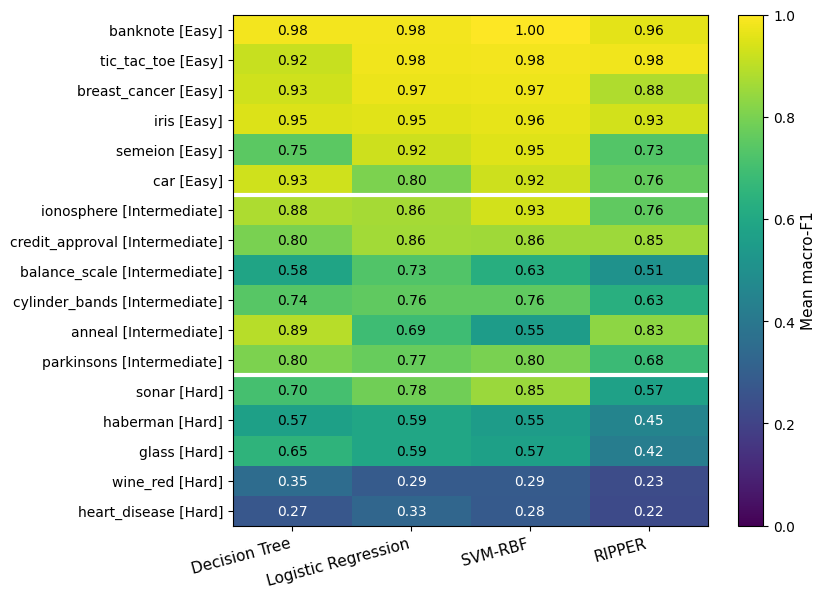

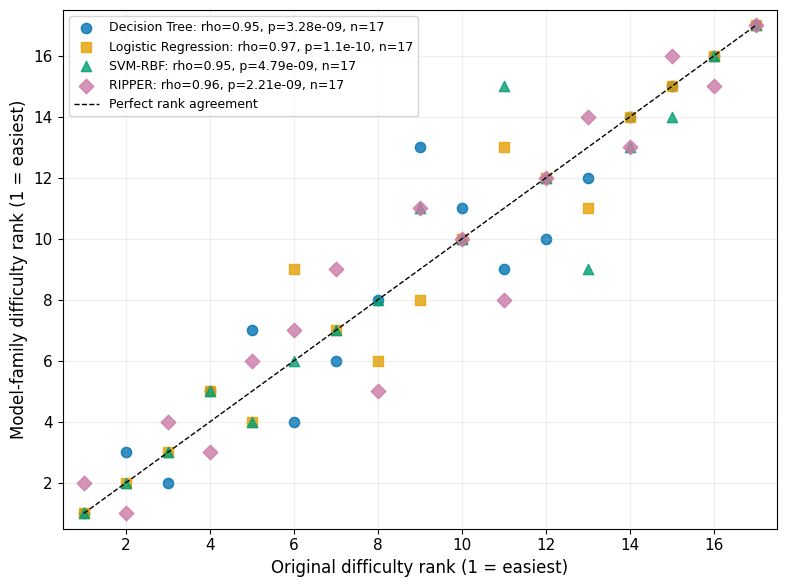

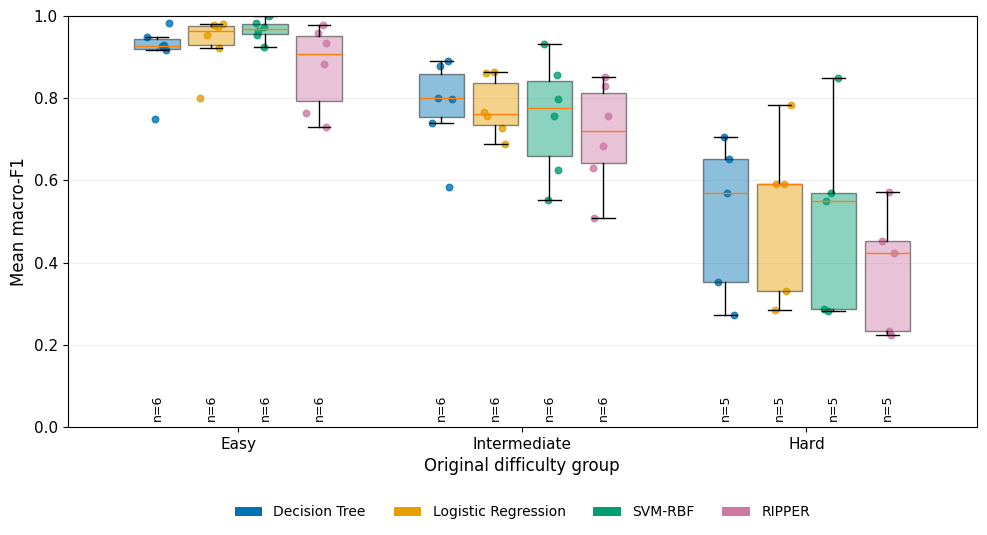

In [23]:
from matplotlib.patches import Patch
CROSS_COLORS = dict(zip(CROSS_FAMILIES, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))
plot_profile = cross_profile.loc[cross_profile.ranking_eligible].sort_values("predictive_difficulty_rank")
coverage = ", ".join(f"{r.model_family}: {r.n_datasets}/{len(cross_eligible)}"
                     for r in cross_rank_correlations_df.itertuples())
def save_cross_figure(fig, filename):
    fig.savefig(CROSS_DIR / f"{filename}.png", dpi=300, bbox_inches="tight")
    fig.savefig(CROSS_DIR / f"{filename}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)



#Fig 6

with plt.rc_context({"font.size": 11, "axes.titlesize": 12, "pdf.fonttype": 42}):
    heat = cross_family_df.pivot(
        index="dataset",
        columns="model_family",
        values="f1_macro_mean"
    ).reindex(
        index=plot_profile.dataset,
        columns=list(CROSS_FAMILIES)
    )

    fig, ax = plt.subplots(figsize=(8.5, max(5, 0.36 * len(heat))))

    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#e6e6e6")

    im = ax.imshow(
        np.ma.masked_invalid(heat.to_numpy()),
        vmin=0,
        vmax=1,
        cmap=cmap,
        aspect="auto"
    )

    ax.set_xticks(
        np.arange(4),
        list(CROSS_FAMILIES),
        rotation=15,
        ha="right"
    )

    ax.set_yticks(
        np.arange(len(heat)),
        [f"{r.dataset} [{r.predictive_difficulty_label.title()}]"
         for r in plot_profile.itertuples()]
    )

    labels = plot_profile.predictive_difficulty_label.to_numpy()
    for j in range(1, len(labels)):
        if labels[j] != labels[j - 1]:
            ax.axhline(j - 0.5, color="white", linewidth=3)

    for i in range(len(heat)):
        for j in range(4):
            v = heat.iloc[i, j]
            ax.text(
                j,
                i,
                f"{v:.2f}" if pd.notna(v) else "NA",
                ha="center",
                va="center",
                fontsize=10,
                color="white" if pd.notna(v) and v < 0.5 else "black"
            )

    cbar = fig.colorbar(im, ax=ax, label="Mean macro-F1")
    cbar.ax.tick_params(labelsize=10)
    cbar.set_label("Mean macro-F1", fontsize=11)

    ax.tick_params(axis="x", labelsize=11)
    ax.tick_params(axis="y", labelsize=10)

    fig.tight_layout()
    save_cross_figure(fig, "cross_model_macro_f1_heatmap")

    # Fig4
    fig, ax = plt.subplots(figsize=(8, 6))

    for (family, color), marker in zip(CROSS_COLORS.items(), ["o", "s", "^", "D"]):
        part = complete_cross.loc[complete_cross.model_family.eq(family)]
        corr = cross_rank_correlations_df.set_index("model_family").loc[family]
        ax.scatter(
            part.original_difficulty_rank,
            part.family_difficulty_rank,
            color=color,
            marker=marker,
            alpha=0.8,
            s=55,
            label=f"{family}: rho={corr.spearman_rho:.2f}, p={corr.p_value:.3g}, n={corr.n_datasets}"
        )

    end = max(1, len(cross_eligible))
    ax.plot([1, end], [1, end], "k--", linewidth=1, label="Perfect rank agreement")

    ax.set(
        xlabel="Original difficulty rank (1 = easiest)",
        ylabel="Model-family difficulty rank (1 = easiest)",
        xlim=(0.5, end + 0.5),
        ylim=(0.5, end + 0.5)
    )

    ax.tick_params(axis="both", labelsize=11)
    ax.xaxis.label.set_size(12)
    ax.yaxis.label.set_size(12)

    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

    fig.tight_layout()
    save_cross_figure(fig, "cross_model_difficulty_ranking_consistency")

    # Fig5



    fig, ax = plt.subplots(figsize=(10, 5.5))
    rng = np.random.default_rng(42)

    for j, (family, color) in enumerate(CROSS_COLORS.items()):
        for i, label in enumerate(CROSS_LABELS):
            values = complete_cross.loc[
                complete_cross.model_family.eq(family)
                & complete_cross.original_difficulty_label.eq(label),
                "f1_macro_mean"
            ].to_numpy()

            position = i + (j - 1.5) * 0.19

            if len(values):
                box = ax.boxplot(
                    [values],
                    positions=[position],
                    widths=0.16,
                    patch_artist=True,
                    manage_ticks=False,
                    showfliers=False
                )

                box["boxes"][0].set(
                    facecolor=color,
                    alpha=0.45
                )

                ax.scatter(
                    position + rng.uniform(-0.045, 0.045, len(values)),
                    values,
                    s=22,
                    color=color,
                    alpha=0.8
                )

            ax.text(
                position,
                0.015,
                f"n={len(values)}",
                ha="center",
                va="bottom",
                fontsize=9,
                rotation=90
            )

    ax.set_xticks(
        range(3),
        [x.title() for x in CROSS_LABELS]
    )

    ax.set(
        xlabel="Original difficulty group",
        ylabel="Mean macro-F1",
        ylim=(0, 1),
        xlim=(-0.6, 2.6)
    )

    ax.tick_params(axis="both", labelsize=11)
    ax.xaxis.label.set_size(12)
    ax.yaxis.label.set_size(12)

    ax.legend(
        handles=[
            Patch(facecolor=color, label=family)
            for family, color in CROSS_COLORS.items()
        ],
        fontsize=10,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.16),
        ncol=4,
        frameon=False
    )

    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()
    save_cross_figure(fig, "predictive_performance_difficulty_groups")


### Interpretation and limitations

The summary below uses observed results without assuming agreement. Spearman p-values
use SciPy's asymptotic approximation and are descriptive (small pool, no multiple-testing correction); repeated CV folds are
dependent. DT/LR contribute to the original score, so their correlations are not independent
validation. SVM/RIPPER are external families but use the same datasets and splits, not an
independent dataset sample. Defaults, class imbalance, imputation, RIPPER discretization/OvR,
unequal configuration counts and missing fits limit inference. Low agreement can indicate
family-dependent difficulty. Relative scores/groups depend on the benchmark pool;
full coverage is needed before manuscript conclusions.

In [24]:
interpretation=[]
for row in cross_rank_correlations_df.itertuples():
    qualification="full pool" if row.full_coverage else "PARTIAL POOL; exploratory only"
    if row.n_datasets>=3:
        interpretation.append(f"{row.model_family}: Spearman rho={row.spearman_rho:.3f}, p={row.p_value:.4g}, "
            f"n={row.n_datasets}/{row.eligible_pool_n} ({qualification}). " + ("External family evidence."
            if row.independent_of_original_score else "Contributes to original score; not independent validation."))
    else:
        interpretation.append(f"{row.model_family}: insufficient complete datasets (n={row.n_datasets}).")
    means=cross_group_summary_df.loc[cross_group_summary_df.model_family.eq(row.model_family)].set_index(
        "original_difficulty_label").reindex(CROSS_LABELS).mean_macro_f1
    if means.notna().all():
        monotonic=means.iloc[0]>means.iloc[1]>means.iloc[2]
        interpretation.append("  Easy/Intermediate/Hard mean F1: "+"/".join(f"{v:.3f}" for v in means)
            +f"; Easy > Intermediate > Hard: {monotonic} (descriptive; {qualification}).")
    else:interpretation.append("  Missing observations in at least one group; group pattern unresolved.")
# Rank shifts use the observed intersection, avoiding artificial shifts from omitted datasets.
shift_parts=[]
for family in CROSS_FAMILIES:
    part=complete_cross.loc[complete_cross.model_family.eq(family)].copy()
    if len(part)<3:continue
    part["original_rank_on_observed_pool"]=part.original_difficulty_rank.rank(method="first")
    part["rank_shift"]=part.family_difficulty_rank-part.original_rank_on_observed_pool
    part["shift_threshold"]=max(2,int(np.ceil(.25*(len(part)-1))))
    part["notable_shift"]=part.rank_shift.abs().ge(part.shift_threshold)
    shift_parts.append(part[["dataset","model_family","family_pool_n","original_rank_on_observed_pool",
                            "family_difficulty_rank","rank_shift","shift_threshold","notable_shift"]])
cross_rank_shifts_df=pd.concat(shift_parts,ignore_index=True) if shift_parts else pd.DataFrame(columns=[
    "dataset","model_family","family_pool_n","original_rank_on_observed_pool","family_difficulty_rank",
    "rank_shift","shift_threshold","notable_shift"])
cross_csv(cross_rank_shifts_df,"rank_shifts.csv")
notable=cross_rank_shifts_df.loc[cross_rank_shifts_df.notable_shift.eq(True)]
interpretation.append("Notable shifts: >=25% of observed rank span, minimum 2 positions; positive = more difficult. "
    +f"Observed: {len(notable)} dataset-family pairs. Absence of flagged shifts does not establish equivalence.")
interpretation.append("Limitations: defaults only; small selected pool; dependent folds; DT/LR enter original score; "
    "unequal configuration counts; preprocessing/OvR; missing results and family-specific normalization. "
    "Low correlation may reflect model-family dependence.")
print("\n".join(interpretation))
display(notable)
(CROSS_DIR/"interpretation.txt").write_text("\n".join(interpretation),encoding="utf-8")
pd.testing.assert_frame_equal(dataset_profile_df,cross_profile)
print("Artifacts:",CROSS_DIR)

Decision Tree: Spearman rho=0.953, p=3.285e-09, n=17/17 (full pool). Contributes to original score; not independent validation.
  Easy/Intermediate/Hard mean F1: 0.909/0.782/0.510; Easy > Intermediate > Hard: True (descriptive; full pool).
Logistic Regression: Spearman rho=0.971, p=1.1e-10, n=17/17 (full pool). Contributes to original score; not independent validation.
  Easy/Intermediate/Hard mean F1: 0.935/0.777/0.517; Easy > Intermediate > Hard: True (descriptive; full pool).
SVM-RBF: Spearman rho=0.951, p=4.792e-09, n=17/17 (full pool). External family evidence.
  Easy/Intermediate/Hard mean F1: 0.966/0.754/0.508; Easy > Intermediate > Hard: True (descriptive; full pool).
RIPPER: Spearman rho=0.956, p=2.206e-09, n=17/17 (full pool). External family evidence.
  Easy/Intermediate/Hard mean F1: 0.875/0.710/0.381; Easy > Intermediate > Hard: True (descriptive; full pool).
Notable shifts: >=25% of observed rank span, minimum 2 positions; positive = more difficult. Observed: 3 dataset-fa

,dataset,model_family,family_pool_n,original_rank_on_observed_pool,family_difficulty_rank,rank_shift,shift_threshold,notable_shift
1,balance_scale,Decision Tree,17,9.0,13.0,4.0,4,True
34,anneal,SVM-RBF,17,11.0,15.0,4.0,4,True
42,sonar,SVM-RBF,17,13.0,9.0,-4.0,4,True


Artifacts: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\results\dataset_statistics\cross_model_validation


In [25]:

import sys
import platform
import os

print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())
print("Processor:", platform.processor())
print("Logical CPU cores:", os.cpu_count())

try:
    import psutil
    ram_gb = psutil.virtual_memory().total / (1024**3)
    print(f"RAM: {ram_gb:.2f} GB")
except ImportError:
    print("RAM: psutil not installed")


Python: 3.12.12
Operating system: Windows-11-10.0.26300-SP0
Processor: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
Logical CPU cores: 20
RAM: 15.69 GB


In [26]:
import subprocess

cpu = subprocess.check_output(
    ["powershell", "-Command",
     "(Get-CimInstance Win32_Processor).Name"],
    text=True
).strip()

print("CPU:", cpu)

CPU: 13th Gen Intel(R) Core(TM) i7-13650HX


In [27]:
import inspect
print(inspect.getsource(build_preprocessor))

def build_preprocessor(X, for_linear=False):
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if for_linear:
        numeric_steps.append(("scaler", StandardScaler()))

    # Use sparse_output when available; fall back for older scikit-learn.
    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

    transformers = []
    if numeric_cols:
        transformers.append(("num", Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", onehot),
            ]),
            categorical_cols,
        ))

    return ColumnTransformer(t